# The Collision-Based Hybrid Method

The collision-based hybrid method splits the angular flux into an uncollided
part, from particles that have not scattered yet, and a collided part:

$$
\psi = \psi^{u} + \psi^{c} .
$$

The uncollided flux carries the sharp angular detail of the source, so it is
solved with a fine quadrature (and fine energy groups). Scattering smooths the
collided flux in angle, so it can be solved with a much coarser quadrature
(and coarser groups). Each time step does one cheap uncollided sweep at high
resolution, then iterates on scattering only at low resolution. See
[Collision-Based Hybrid Method](../../hybrid-method/index.rst) for the
derivation.

The solver is `ants.hybrid1d.time_dependent`. It takes separate material data
and quadratures for the uncollided and collided problems, plus a `HybridData`
object that maps fine energy groups to coarse ones. This example is
monoenergetic, so only the angles are split.

In [1]:
import os
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

import ants
from ants import hybrid1d, timed1d
from ants.datatypes import (
    GeometryData,
    MaterialData,
    SolverData,
    SourceData,
    TimeDependentData,
)
from ants.utils import hybrid as hytools

# Plot colors: one per method, plus a neutral dashed reference
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
REFERENCE = dict(color="#52514e", ls="--", lw=2)


def tidy(ax):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

## Problem setup

Reed's problem is a 16 cm slab with vacuum boundaries and five regions,
symmetric about $x = 8$ cm:

| Region | Location (cm) | $\sigma_t$ | $\sigma_s$ | Source |
|---|---|---|---|---|
| Scatterer | 0-4, 12-16 | 1 | 0.9 | 1 in 2-4 and 12-14, otherwise 0 |
| Void | 4-5, 11-12 | 0 | 0 | 0 |
| Absorber | 5-6, 10-11 | 5 | 0 | 0 |
| Source | 6-10 | 50 | 0 | 50 |

The thin void, the thick absorber and the very thick source region make it a
standard stress test for transport discretizations.

The source switches on at $t = 0$ with zero initial flux and $v = 1$, and the
problem runs to $t = 20$ with backward Euler and $\Delta t = 0.1$. Each run
writes its flux at every step with `TimeDependentData(save_to_file=...)`.

In [2]:
cells = 320
edges_x = np.linspace(0.0, 16.0, cells + 1)
centers_x = 0.5 * (edges_x[1:] + edges_x[:-1])
layers = [
    [0, "scatterer", "0-4, 12-16"],
    [1, "void", "4-5, 11-12"],
    [2, "absorber", "5-6, 10-11"],
    [3, "source", "6-10"],
]
medium_map = ants.spatial1d(layers, edges_x)
materials = MaterialData(
    total=np.array([[1.0], [0.0], [5.0], [50.0]]),
    scatter=np.array([[[0.9]], [[0.0]], [[0.0]], [[0.0]]]),
    fission=np.zeros((4, 1, 1)),
    velocity=np.ones(1),
)
geometry = GeometryData(
    medium_map=medium_map, delta_x=np.diff(edges_x), bc_x=[0, 0], geometry=1
)
external = ants.external1d.time_dependence_constant(
    ants.external1d.reeds(edges_x, [0, 0])
)
steps, dt = 200, 0.1
times = dt * np.arange(1, steps + 1)
workdir = tempfile.mkdtemp()

# One energy group for both the uncollided and collided problems
edges_g, edges_gidx_u, edges_gidx_c = ants.energy_grid(None, 1, 1)
hybrid_data = hytools.indexing(edges_g, edges_gidx_u, edges_gidx_c)


def sources(angles):
    return SourceData(
        initial_flux=np.zeros((cells, angles, 1)),
        external=external,
        boundary_x=np.zeros((1, 2, 1, 1)),
    )


def timed(run, repeats=3):
    """Run a solve several times; return its flux history and best wall time."""
    best = np.inf
    for _ in range(repeats):
        start = time.perf_counter()
        path = run()
        best = min(best, time.perf_counter() - start)
    return np.load(path)[..., 0], best  # flux history: (steps, cells)


def full(angles):
    """Standard S_N with one quadrature for all particles."""
    path = os.path.join(workdir, f"full_{angles}.npy")

    def run():
        timed1d.time_dependent(
            materials, sources(angles), geometry, ants.angular_x(angles),
            SolverData(), TimeDependentData(steps=steps, dt=dt, save_to_file=path),
        )
        return path

    return timed(run)


def hybrid(angles_u, angles_c):
    """Hybrid method: angles_u for uncollided, angles_c for collided."""
    path = os.path.join(workdir, f"hybrid_{angles_u}_{angles_c}.npy")

    def run():
        hybrid1d.time_dependent(
            materials, materials, sources(angles_u), geometry,
            ants.angular_x(angles_u), ants.angular_x(angles_c), SolverData(),
            TimeDependentData(steps=steps, dt=dt, save_to_file=path), hybrid_data,
        )
        return path

    return timed(run)

## Hybrid against standard S$_N$

The reference is standard S$_N$ with 64 angles. It is compared with standard
S$_N$ at 4 and 16 angles, and with the hybrid method using 64 uncollided
angles and only 4 collided angles.

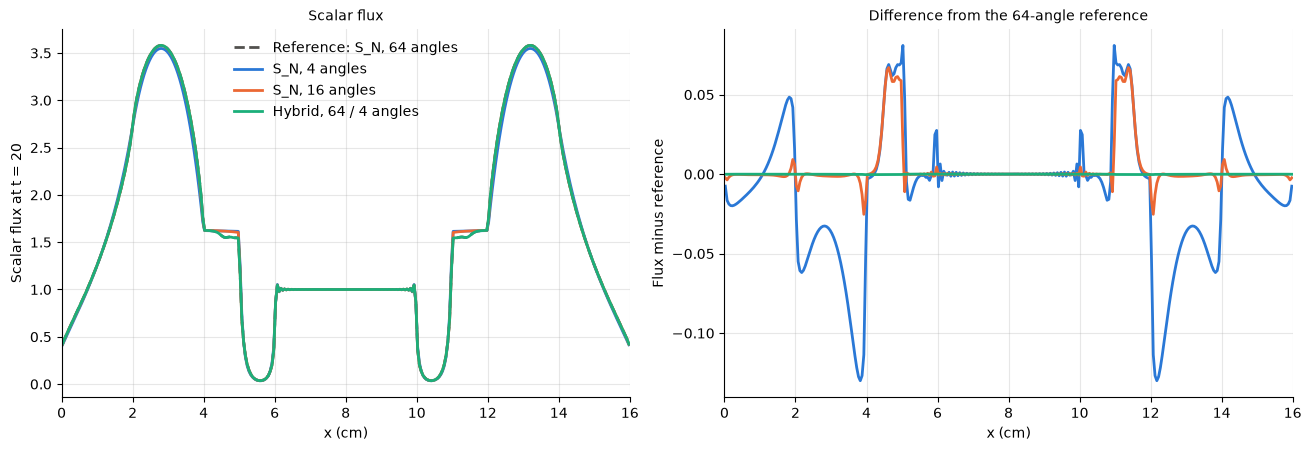

Method                    Time (s)  Rel. L2 error
Reference: S_N, 64           0.234       0.00e+00
S_N, 4 angles                0.026       2.16e-02
S_N, 16 angles               0.066       8.44e-03
Hybrid, 64 / 4 angles        0.088       5.87e-05


In [3]:
ref_flux, ref_time = full(64)
runs = {
    "S_N, 4 angles": full(4),
    "S_N, 16 angles": full(16),
    "Hybrid, 64 / 4 angles": hybrid(64, 4),
}


def rel_error(flux):
    return np.linalg.norm(flux[-1] - ref_flux[-1]) / np.linalg.norm(ref_flux[-1])


fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
ax0.plot(centers_x, ref_flux[-1], label="Reference: S_N, 64 angles", **REFERENCE)
ax1.axhline(0.0, color="#52514e", lw=0.8)
for color, (name, (flux, _)) in zip(COLORS, runs.items()):
    ax0.plot(centers_x, flux[-1], color=color, lw=2, label=name)
    ax1.plot(centers_x, flux[-1] - ref_flux[-1], color=color, lw=2, label=name)
ax0.set_ylabel("Scalar flux at t = 20")
ax0.set_title("Scalar flux", fontsize=10)
ax0.legend(frameon=False)
ax1.set_ylabel("Flux minus reference")
ax1.set_title("Difference from the 64-angle reference", fontsize=10)
for ax in (ax0, ax1):
    ax.set_xlabel("x (cm)")
    ax.set_xlim(0, 16)
    tidy(ax)
plt.show()

print(f"{'Method':24s} {'Time (s)':>9s} {'Rel. L2 error':>14s}")
print(f"{'Reference: S_N, 64':24s} {ref_time:9.3f} {0.0:14.2e}")
for name, (flux, wall) in runs.items():
    print(f"{name:24s} {wall:9.3f} {rel_error(flux):14.2e}")

At full scale the curves overlap, so the right panel shows each method's
difference from the reference. With 16 angles, standard S$_N$ is off mainly in
the void regions at 4-5 and 11-12 cm, where the flux comes from particles
streaming without collisions and so depends most directly on the quadrature.
With 4 angles it is also off throughout the scatterers. The hybrid method with
only 4 collided angles sits on the zero line: its error is more than 100 times
smaller than standard S$_N$ with 16 angles, and it runs in less than half the
time of the 64-angle reference. Its accuracy is set by the uncollided
quadrature: by the time particles have scattered, their angular distribution
is smooth enough for 4 angles to capture it.

## How coarse can the collided quadrature be?

The sweep below keeps 64 uncollided angles and varies the collided angles,
and compares the cost and error against standard S$_N$ at several angle
counts. Points further down and to the left are better. Wall times are the
best of three runs, so they vary a little between machines.

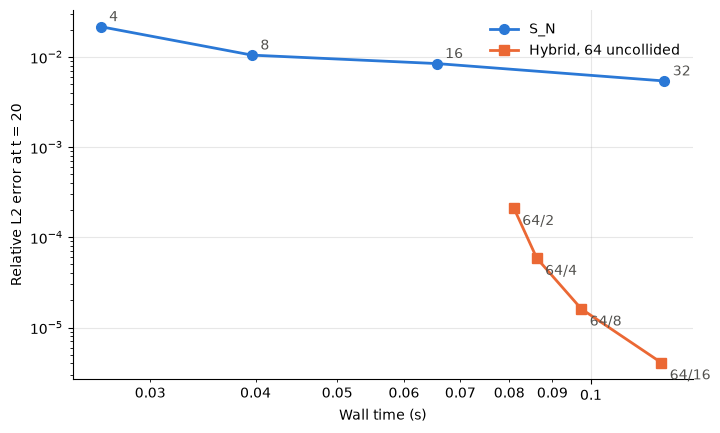

In [4]:
full_angles = [4, 8, 16, 32]
collided_angles = [2, 4, 8, 16]
full_runs = {n: full(n) for n in full_angles}
hybrid_runs = {n: hybrid(64, n) for n in collided_angles}

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog([full_runs[n][1] for n in full_angles],
          [rel_error(full_runs[n][0]) for n in full_angles],
          color=COLORS[0], lw=2, marker="o", ms=7, label="S_N")
ax.loglog([hybrid_runs[n][1] for n in collided_angles],
          [rel_error(hybrid_runs[n][0]) for n in collided_angles],
          color=COLORS[1], lw=2, marker="s", ms=7, label="Hybrid, 64 uncollided")
for n in full_angles:
    flux, wall = full_runs[n]
    ax.annotate(f"{n}", (wall, rel_error(flux)), xytext=(6, 4),
                textcoords="offset points", color="#52514e")
for n in collided_angles:
    flux, wall = hybrid_runs[n]
    ax.annotate(f"64/{n}", (wall, rel_error(flux)), xytext=(6, -12),
                textcoords="offset points", color="#52514e")
plain = FuncFormatter(lambda value, _: f"{value:g}")
ax.xaxis.set_major_formatter(plain)
ax.xaxis.set_minor_formatter(plain)
ax.set_xlabel("Wall time (s)")
ax.set_ylabel("Relative L2 error at t = 20")
ax.legend(frameon=False)
tidy(ax)
plt.show()

Refining standard S$_N$ reduces the error slowly: going from 4 to 32 angles
costs several times more and cuts the error by only a factor of about 4. The
hybrid points sit far below the S$_N$ line. Even 2 collided angles beat
32-angle S$_N$ by more than an order of magnitude, and each doubling of the
collided angles cuts the error by roughly 3-4 while the cost grows slowly.

This example only splits angles. In multigroup problems the collided problem
can also use fewer energy groups (see `hybrid_1d_uranium_slab.py`), which
saves more again.

## Scattering reaction rate

The scattering reaction rate density is $R_s(x) = \sum_g \sigma_{s,g}(x)\,
\phi_g(x)$, where $\sigma_{s,g}$ is the total scattering cross section out of
group $g$. The helper below computes it from `MaterialData.scatter`, which is
indexed `[material, group out, group in]`.

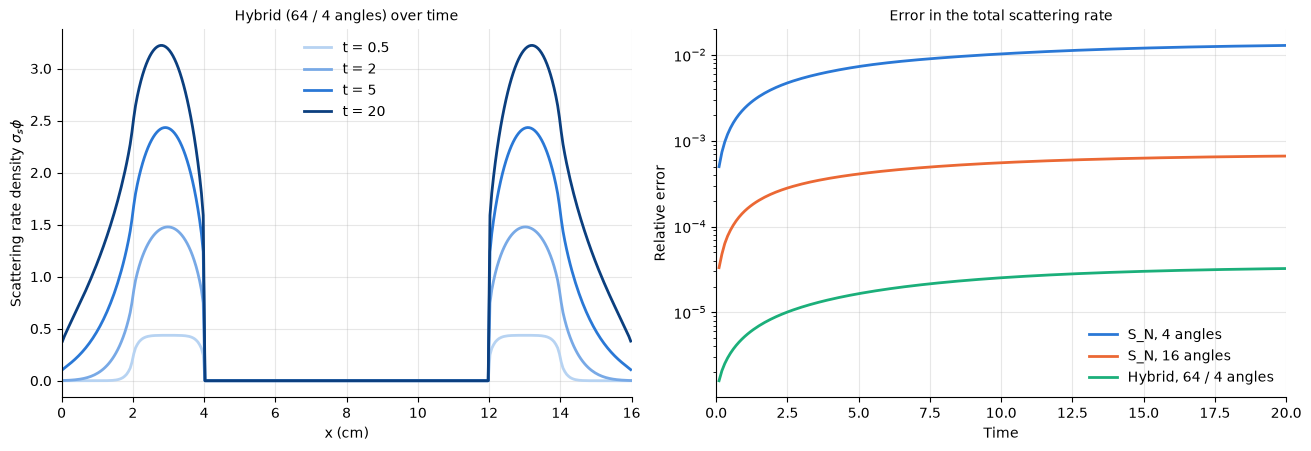

In [5]:
def scattering_rate(flux, scatter, medium_map):
    """Scattering reaction rate density, sigma_s * phi, in each cell.

    scatter is indexed [material, group out, group in], so summing over the
    outgoing group gives the total scattering cross section of each group.
    flux has the cell axes first and groups last.
    """
    sigma_s = scatter.sum(axis=1)  # (materials, groups)
    return np.sum(sigma_s[medium_map] * flux, axis=-1)


hybrid_flux = runs["Hybrid, 64 / 4 angles"][0]
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)

# Left: how the scattering rate fills in over time (hybrid 64 / 4)
snapshots = [0.5, 2.0, 5.0, 20.0]
shades = ["#b7d3f2", "#78a9e6", "#2a78d6", "#0b3f7f"]
for t, shade in zip(snapshots, shades):
    step = round(t / dt) - 1
    rate = scattering_rate(hybrid_flux[step, :, None], materials.scatter, medium_map)
    ax0.plot(centers_x, rate, color=shade, lw=2, label=f"t = {t:g}")
ax0.set_xlim(0, 16)
ax0.set_xlabel("x (cm)")
ax0.set_ylabel("Scattering rate density $\\sigma_s \\phi$")
ax0.set_title("Hybrid (64 / 4 angles) over time", fontsize=10)
ax0.legend(frameon=False)

# Right: error in the slab-integrated scattering rate over time
delta_x = np.diff(edges_x)


def total_scattering(flux_history):
    rate = scattering_rate(flux_history[..., None], materials.scatter, medium_map)
    return rate @ delta_x


ref_total = total_scattering(ref_flux)
for color, (name, (flux, _)) in zip(COLORS, runs.items()):
    error = np.abs(total_scattering(flux) / ref_total - 1)
    ax1.semilogy(times, np.maximum(error, 1e-12), color=color, lw=2, label=name)
ax1.set_xlim(0, 20)
ax1.set_xlabel("Time")
ax1.set_ylabel("Relative error")
ax1.set_title("Error in the total scattering rate", fontsize=10)
ax1.legend(frameon=False)
for ax in (ax0, ax1):
    tidy(ax)
plt.show()

At early times, scattering happens where the scatterers have their own
source (2-4 and 12-14 cm). The rate then spreads and grows as particles move
through the scatterers and arrive from the central source. The error in the
total scattering rate (right) follows the same ranking as the flux: about 1%
for S$_N$ with 4 angles, below 0.1% with 16 angles, and around $10^{-5}$ for
the hybrid method with 64 / 4 angles.